In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import files
uploaded=files.upload()

Saving road.csv to road.csv


In [3]:
#Cleaning
df = pd.read_csv('road.csv')
df.columns = df.columns.str.strip()
df = df.fillna('Unknown')
df = df.drop_duplicates()
# Clean up vehicle column
df['Type_of_vehicle'] = df['Type_of_vehicle'].astype(str).str.replace('?', '-', regex=False)

print("After Cleaning:", df.shape, "| Missing:", df.isna().sum().sum())

After Cleaning: (12315, 14) | Missing: 0


In [4]:
import numpy as np

# Extract Hour
df['Hour'] = pd.to_numeric(df['Time'].astype(str).str.split(':').str[0], errors='coerce')


# Create Time Slot
def get_time_slot(hour):
    if pd.isna(hour):
        return 'Unknown Time'  # Catches missing rows safely!
    elif 6 <= hour < 12:
        return 'Morning (6am-12pm)'
    elif 12 <= hour < 18:
        return 'Afternoon (12pm-6pm)'
    elif 18 <= hour < 22:
        return 'Evening Peak (6pm-10pm)'
    else:
        return 'Night (10pm-6am)'

df['Time Slot'] = df['Hour'].apply(get_time_slot)

# Create Binary Flags
df['Is_Weekend'] = df['Day_of_week'].isin(['Saturday', 'Sunday']).astype(int)
df['Is_Fatal'] = (df['Accident_severity'] == 'Fatal injury').astype(int)

# Clean Remaining Cell Blanks
df = df.fillna('Unknown')
# Print
print("--- NEW COLUMNS SUCCESSFULLY CREATED ---")
print(df[['Time', 'Hour', 'Time Slot', 'Day_of_week', 'Is_Weekend']].head())
print(df[['Accident_severity', 'Is_Fatal']].head())


--- NEW COLUMNS SUCCESSFULLY CREATED ---
       Time  Hour             Time Slot Day_of_week  Is_Weekend
0  17:02:00    17  Afternoon (12pm-6pm)      Monday           0
1  17:02:00    17  Afternoon (12pm-6pm)      Monday           0
2  17:02:00    17  Afternoon (12pm-6pm)      Monday           0
3   1:06:00     1      Night (10pm-6am)      Sunday           1
4   1:06:00     1      Night (10pm-6am)      Sunday           1
  Accident_severity  Is_Fatal
0     Slight Injury         0
1     Slight Injury         0
2    Serious Injury         0
3     Slight Injury         0
4     Slight Injury         0


In [5]:
 #Create simple,Time Slots
def get_time_slot(hour):
    if 6 <= hour < 12:    return 'Morning (6am-12pm)'
    elif 12 <= hour < 18: return 'Afternoon (12pm-6pm)'
    elif 18 <= hour < 22: return 'Evening Peak (6pm-10pm)'
    else:                 return 'Night (10pm-6am)'

df['Time Slot'] = df['Hour'].apply(get_time_slot)

# Create simple Yes/No (1/0) flags for analysis
df['Is_Weekend'] = df['Day_of_week'].isin(['Saturday', 'Sunday']).astype(int)
df['Is_Fatal'] = (df['Accident_severity'] == 'Fatal injury').astype(int)

# Fill any remaining blank cells in the dataset with 'Unknown'
df = df.fillna('Unknown')

print("--- NEW COLUMNS SUCCESSFULLY CREATED ---")
print(df[['Time', 'Hour', 'Time Slot', 'Day_of_week', 'Is_Weekend']].head())
print(df[['Accident_severity', 'Is_Fatal']].head())


--- NEW COLUMNS SUCCESSFULLY CREATED ---
       Time  Hour             Time Slot Day_of_week  Is_Weekend
0  17:02:00    17  Afternoon (12pm-6pm)      Monday           0
1  17:02:00    17  Afternoon (12pm-6pm)      Monday           0
2  17:02:00    17  Afternoon (12pm-6pm)      Monday           0
3   1:06:00     1      Night (10pm-6am)      Sunday           1
4   1:06:00     1      Night (10pm-6am)      Sunday           1
  Accident_severity  Is_Fatal
0     Slight Injury         0
1     Slight Injury         0
2    Serious Injury         0
3     Slight Injury         0
4     Slight Injury         0


In [6]:
#Insights
print("\n--- TOP CAUSE ---")
print(df['Cause_of_accident'].value_counts().head(5))
print("\n--- TIME SLOT ---")
print(df['Time Slot'].value_counts())
print("\n--- SEVERITY ---")
print(df['Accident_severity'].value_counts())
print("\n--- TOP VEHICLE ---")
print(df['Type_of_vehicle'].value_counts().head(5))
print("\n--- DAY ---")
print(df['Day_of_week'].value_counts())
print("\n--- CASUALTY ---")
print(df['Casualty_class'].value_counts())


--- TOP CAUSE ---
Cause_of_accident
No distancing                 2262
Changing lane to the right    1808
Changing lane to the left     1473
Driving carelessly            1402
No priority to vehicle        1207
Name: count, dtype: int64

--- TIME SLOT ---
Time Slot
Afternoon (12pm-6pm)       5124
Morning (6am-12pm)         3236
Evening Peak (6pm-10pm)    2669
Night (10pm-6am)           1286
Name: count, dtype: int64

--- SEVERITY ---
Accident_severity
Slight Injury     10414
Serious Injury     1743
Fatal injury        158
Name: count, dtype: int64

--- TOP VEHICLE ---
Type_of_vehicle
Automobile          3205
Lorry (41-100Q)     2186
Other               1207
Unknown              950
Pick up upto 10Q     811
Name: count, dtype: int64

--- DAY ---
Day_of_week
Friday       2041
Thursday     1851
Wednesday    1840
Tuesday      1770
Monday       1681
Saturday     1666
Sunday       1466
Name: count, dtype: int64

--- CASUALTY ---
Casualty_class
Driver or rider    4944
na                 4442

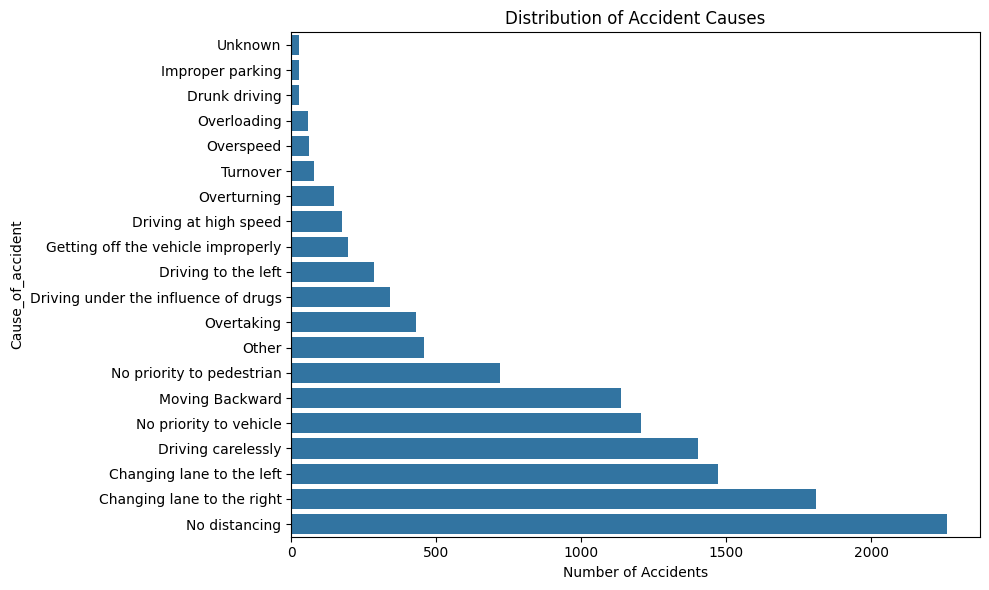

In [7]:
order1 = df['Cause_of_accident'].value_counts().index[::-1]

plt.figure(figsize=(10, 6))
sns.countplot(data=df, y='Cause_of_accident', order=order1)
plt.title('Distribution of Accident Causes')
plt.xlabel('Number of Accidents')

plt.tight_layout()
plt.show()


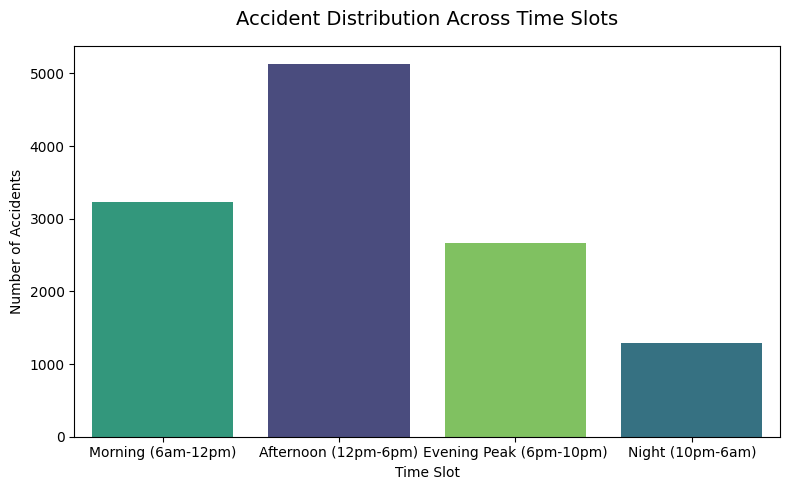

In [8]:
plt.figure(figsize=(8, 5))
order2 = [
    'Morning (6am-12pm)',
    'Afternoon (12pm-6pm)',
    'Evening Peak (6pm-10pm)',
    'Night (10pm-6am)'
]

sns.countplot(
    data=df,
    x='Time Slot',
    order=order2,
    hue='Time Slot',
    palette='viridis',
    legend=False
)


plt.title('Accident Distribution Across Time Slots', fontsize=14, pad=15)
plt.xlabel('Time Slot')
plt.ylabel('Number of Accidents')

plt.tight_layout()
plt.show()


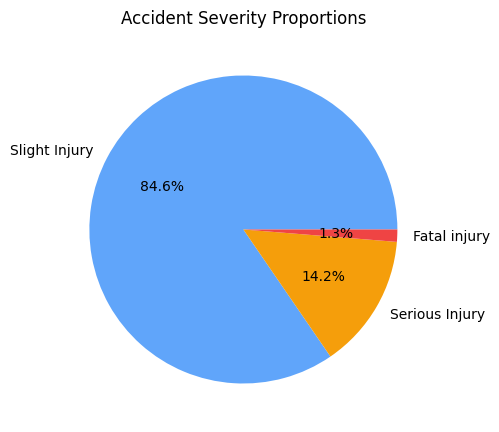

In [9]:
plt.figure(figsize=(5, 5))

# plot: 'colors' adds professional palette, 'ylabel=""'
df['Accident_severity'].value_counts().plot.pie(autopct='%1.1f%%',
colors=['#60A5FA', '#F59E0B', '#EF4444'], ylabel='')

plt.title('Accident Severity Proportions', pad=10)
plt.show()


In [10]:
df.to_csv('clean_road_accident.csv', index=False)
